Отчет по лабораторной работе 1
Дисциплина: Системы искусственного интеллекта и машинное обучение
Тема: Регрессия и метод главных компонентов
Вариант: House price prediction

Работу выполнила Жукова Е.И. группа АП-326

1. Введение

Цель работы: изучение основ линейной регрессии, построение простейших моделей регрессии, проведение обучения модели на реальных данных и оценка её качество.

Постановка задачи:

Провести обучение модели линейной регрессии на датасете с Kaggle:

1. Загрузить датасет из репозитория (например, kaggle.com или аналогичных платформ).

2. Подготовить данные: провести первичный анализ, визуализировать распределение признаков и целевой переменной. 

3. Провести предобработку данных: удалить пропущенные значения, закодировать категориальные переменные (опционально).

4. Построить матрицу корреляций. Сделать выводы о наличии мультиколлинеарности (расчет VIF-коэффициента).

5. Построить регрессионные модели (линейная, лассо и гребневая). Если целевая переменная - категориальная, то исследовать логистическую регрессию. Разделить на тренировочную и тестовую выборки (80/20 или 70/30). Использовать кросс-валидацию. Оценить качество построенной модели с помощью метрик: RMSE (Root Mean Square Error), R² (коэффициент детерминации) и MAPE (Mean Absolute Percentage Error).

6. Построить график остатков моделей (добавить горизонтальную линию на уровне 0) и исследовать структуру остатков на предмет гомоскедастичности или гетероскедастичности.

7. Устранить мультиколлинеарность и снизить размерность признаков с помощью метода главных компонент (PCA). Перед проведением PCA провести стандартизацию данных.

8. Повторить шаг 5 (линейная, лассо и гребневая регрессия), но использовать в качестве признаков не исходные данные, а главные компоненты. Сравнить метрики качества (RMSE, R² и MAPE) моделей, обученных на исходных данных и на главных компонентах.

2. Описание датасета

Датасет House price prediction содержит информацию о домах, включая такие признаки как количество спален, ванных комнат, этажей, общую площадь, состояние и ключевую переменную price.

In [6]:
%pip install kagglehub pandas numpy matplotlib seaborn scikit-learn statsmodels jupyter ipykernel

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Подключаем датасет

In [7]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("debayank2024/house-price-prediction")

print("C:/Users/elena/OneDrive/Рабочий стол/Машинное обучение/Лаб 1", path)

C:/Users/elena/OneDrive/Рабочий стол/Машинное обучение/Лаб 1 C:\Users\elena\.cache\kagglehub\datasets\debayank2024\house-price-prediction\versions\1


Анализируем датасет и подготавливаем его к работе (убираем дубликаты, пропущенные значения и тд.)

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('modified_data.csv')

print(df.shape)

display(df.head())

df.info()

df['date'] = pd.to_datetime(df['date'], errors='coerce')

missing = pd.DataFrame({
    'missing': df.isna().sum(),
    'missing_percent': df.isna().mean() * 100
})
display(missing)

print('Дубликаты:', df.duplicated().sum())

display(df.describe().T)

numeric_cols = df.select_dtypes(include=np.number).columns

summary = df[numeric_cols].describe().T
summary['median'] = df[numeric_cols].median()
summary['skewness'] = df[numeric_cols].skew()
summary['zero_count'] = (df[numeric_cols] == 0).sum()

display(summary)

(4600, 18)


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,price_per_sqft
0,2014-05-02,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,233.58
1,2014-05-02,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,653.15
2,2014-05-02,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,177.20
3,2014-05-02,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,210.00
4,2014-05-02,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,283.51


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date            4600 non-null   object 
 1   price           4600 non-null   float64
 2   bedrooms        4600 non-null   float64
 3   bathrooms       4600 non-null   float64
 4   sqft_living     4600 non-null   int64  
 5   sqft_lot        4600 non-null   int64  
 6   floors          4600 non-null   float64
 7   waterfront      4600 non-null   int64  
 8   view            4600 non-null   int64  
 9   condition       4600 non-null   int64  
 10  sqft_above      4600 non-null   int64  
 11  sqft_basement   4600 non-null   int64  
 12  yr_built        4600 non-null   int64  
 13  yr_renovated    4600 non-null   int64  
 14  street          4600 non-null   object 
 15  city            4600 non-null   object 
 16  statezip        4600 non-null   object 
 17  price_per_sqft  4600 non-null   f

,missing,missing_percent
date,0,0.0
price,0,0.0
bedrooms,0,0.0
bathrooms,0,0.0
sqft_living,0,0.0
sqft_lot,0,0.0
floors,0,0.0
waterfront,0,0.0
view,0,0.0
condition,0,0.0


Дубликаты: 0


,count,mean,min,25%,50%,75%,max,std
date,4600,2014-06-07 03:14:42.782608640,2014-05-02 00:00:00,2014-05-21 00:00:00,2014-06-09 00:00:00,2014-06-24 00:00:00,2014-07-10 00:00:00,NaN
price,4600.0,551962.98847,0.0,322875.0,460943.46,654962.5,26590000.0,563834.702545
bedrooms,4600.0,3.40087,0.0,3.0,3.0,4.0,9.0,0.908848
bathrooms,4600.0,2.160815,0.0,1.75,2.25,2.5,8.0,0.783781
sqft_living,4600.0,2139.346957,370.0,1460.0,1980.0,2620.0,13540.0,963.206916
sqft_lot,4600.0,14852.516087,638.0,5000.75,7683.0,11001.25,1074218.0,35884.436145
floors,4600.0,1.512065,1.0,1.0,1.5,2.0,3.5,0.538288
waterfront,4600.0,0.007174,0.0,0.0,0.0,0.0,1.0,0.084404
view,4600.0,0.240652,0.0,0.0,0.0,0.0,4.0,0.778405
condition,4600.0,3.451739,1.0,3.0,3.0,4.0,5.0,0.67723


,count,mean,std,min,25%,50%,75%,max,median,skewness,zero_count
price,4600.0,551962.988470,563834.702545,0.0,322875.0000,460943.460,654962.50,26590000.0,460943.460,24.790933,49
bedrooms,4600.0,3.400870,0.908848,0.0,3.0000,3.000,4.00,9.0,3.000,0.456447,2
bathrooms,4600.0,2.160815,0.783781,0.0,1.7500,2.250,2.50,8.0,2.250,0.616033,2
sqft_living,4600.0,2139.346957,963.206916,370.0,1460.0000,1980.000,2620.00,13540.0,1980.000,1.723513,0
sqft_lot,4600.0,14852.516087,35884.436145,638.0,5000.7500,7683.000,11001.25,1074218.0,7683.000,11.307139,0
floors,4600.0,1.512065,0.538288,1.0,1.0000,1.500,2.00,3.5,1.500,0.551441,0
waterfront,4600.0,0.007174,0.084404,0.0,0.0000,0.000,0.00,1.0,0.000,11.682901,4567
view,4600.0,0.240652,0.778405,0.0,0.0000,0.000,0.00,4.0,0.000,3.341586,4140
condition,4600.0,3.451739,0.677230,1.0,3.0000,3.000,4.00,5.0,3.000,0.959068,0
sqft_above,4600.0,1827.265435,862.168977,370.0,1190.0000,1590.000,2300.00,9410.0,1590.000,1.494211,0


Анализ целевой переменной

Количество price = 0: 49
Средняя цена: 551962.9884695652
Медианная цена: 460943.45999999996
Максимальная цена: 26590000.0
Асимметрия: 24.790932562043295


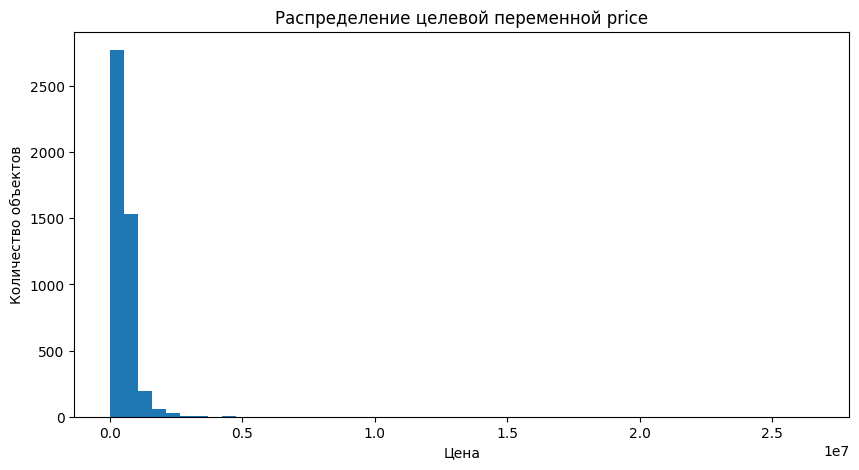

In [9]:
print('Количество price = 0:', (df['price'] == 0).sum())
print('Средняя цена:', df['price'].mean())
print('Медианная цена:', df['price'].median())
print('Максимальная цена:', df['price'].max())
print('Асимметрия:', df['price'].skew())

plt.figure(figsize=(10, 5))
plt.hist(df['price'], bins=50)
plt.title('Распределение целевой переменной price')
plt.xlabel('Цена')
plt.ylabel('Количество объектов')
plt.show()

Распределение основных количественных признаков

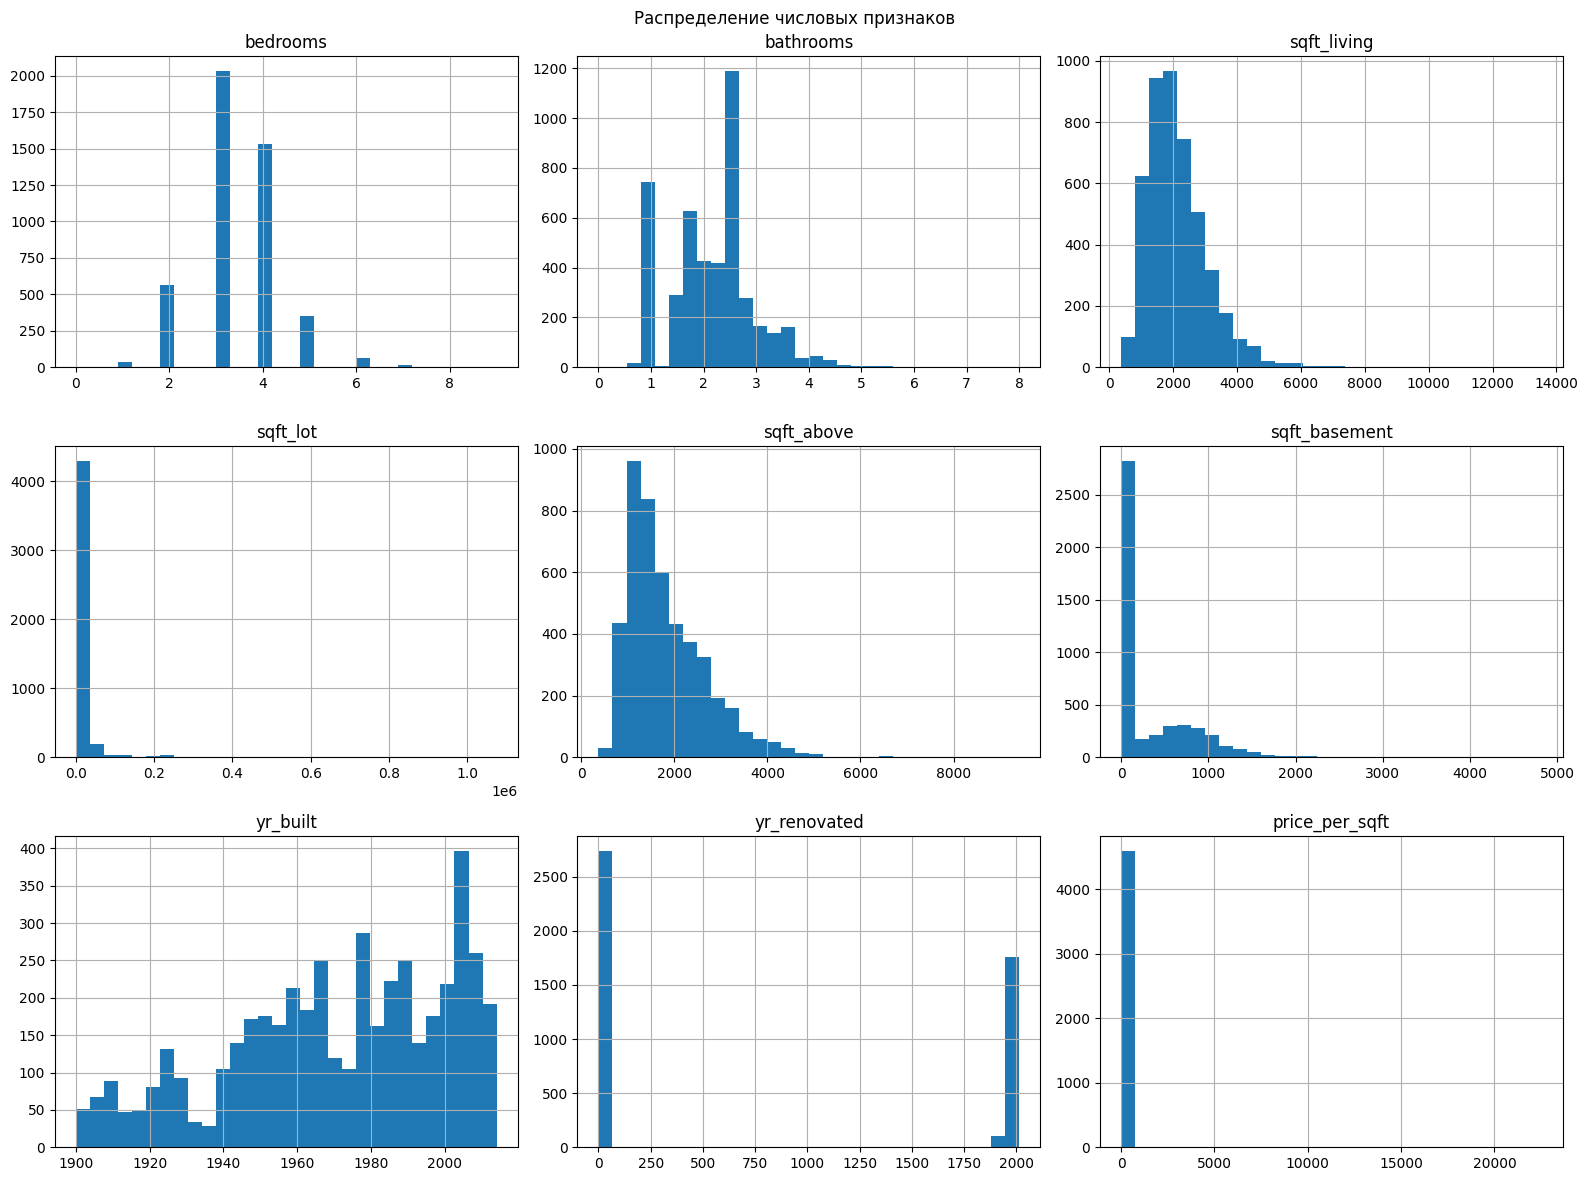

In [10]:
numeric_features = [
    'bedrooms',
    'bathrooms',
    'sqft_living',
    'sqft_lot',
    'sqft_above',
    'sqft_basement',
    'yr_built',
    'yr_renovated',
    'price_per_sqft'
]

df[numeric_features].hist(
    figsize=(16, 12),
    bins=30
)

plt.suptitle('Распределение числовых признаков')
plt.tight_layout()
plt.show()

3. Подготовка данных

Предоработка данных. Удаляем столбцы с категориальными признаками (city, statezip, street), столбцы с датами (yr_built, yr_renovated, date), столбец sqft_above чтобы не допустить ошибки и строки с нулевыми значениями целевой переменной.

In [11]:
# Создаем копию исходного датасета
df_clean = df.copy()

# 1. Удаляем категориальные признаки
df_clean = df_clean.drop(columns=['city', 'statezip', 'street'])

df_clean = df_clean.drop(columns=['yr_built', 'yr_renovated', 'date'])

# 2. Удаляем признак price_per_sqft,
# так как он напрямую зависит от целевой переменной price
df_clean = df_clean.drop(columns=['price_per_sqft', 'sqft_above'])

# 4. Удаляем строки, где price = 0
df_clean = df_clean[df_clean['price'] != 0]

# Обновляем индексы после удаления строк
df_clean = df_clean.reset_index(drop=True)

df_clean.head()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_basement
0,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,0
1,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,280
2,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,0
3,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000
4,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,800


Проверка результата

In [12]:
df_clean.info()

df_clean.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4551 entries, 0 to 4550
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   price          4551 non-null   float64
 1   bedrooms       4551 non-null   float64
 2   bathrooms      4551 non-null   float64
 3   sqft_living    4551 non-null   int64  
 4   sqft_lot       4551 non-null   int64  
 5   floors         4551 non-null   float64
 6   waterfront     4551 non-null   int64  
 7   view           4551 non-null   int64  
 8   condition      4551 non-null   int64  
 9   sqft_basement  4551 non-null   int64  
dtypes: float64(4), int64(6)
memory usage: 355.7 KB


,count,mean,std,min,25%,50%,75%,max
price,4551.0,557905.899134,563929.871277,7800.0,326264.285,465000.00,657500.0,26590000.0
bedrooms,4551.0,3.394639,0.904595,0.0,3.000,3.00,4.0,9.0
bathrooms,4551.0,2.155021,0.776351,0.0,1.750,2.25,2.5,8.0
sqft_living,4551.0,2132.372226,955.949708,370.0,1460.000,1970.00,2610.0,13540.0
sqft_lot,4551.0,14835.280598,35964.077825,638.0,5000.000,7680.00,10978.0,1074218.0
floors,4551.0,1.512195,0.538531,1.0,1.000,1.50,2.0,3.5
waterfront,4551.0,0.006592,0.080932,0.0,0.000,0.00,0.0,1.0
view,4551.0,0.234674,0.765373,0.0,0.000,0.00,0.0,4.0
condition,4551.0,3.449352,0.675160,1.0,3.000,3.00,4.0,5.0
sqft_basement,4551.0,310.150516,461.987629,0.0,0.000,0.00,600.0,4820.0


Построение матрицы корреляций

               price  bedrooms  bathrooms  sqft_living  sqft_lot  floors  \
price          1.000     0.210      0.341        0.445     0.051   0.153   
bedrooms       0.210     1.000      0.548        0.596     0.071   0.176   
bathrooms      0.341     0.548      1.000        0.757     0.109   0.490   
sqft_living    0.445     0.596      0.757        1.000     0.213   0.344   
sqft_lot       0.051     0.071      0.109        0.213     1.000   0.004   
floors         0.153     0.176      0.490        0.344     0.004   1.000   
waterfront     0.150    -0.006      0.063        0.108     0.017   0.016   
view           0.243     0.115      0.206        0.309     0.073   0.032   
condition      0.039     0.023     -0.121       -0.063     0.001  -0.274   
sqft_basement  0.218     0.335      0.296        0.450     0.036  -0.255   

               waterfront   view  condition  sqft_basement  
price               0.150  0.243      0.039          0.218  
bedrooms           -0.006  0.115      0.0

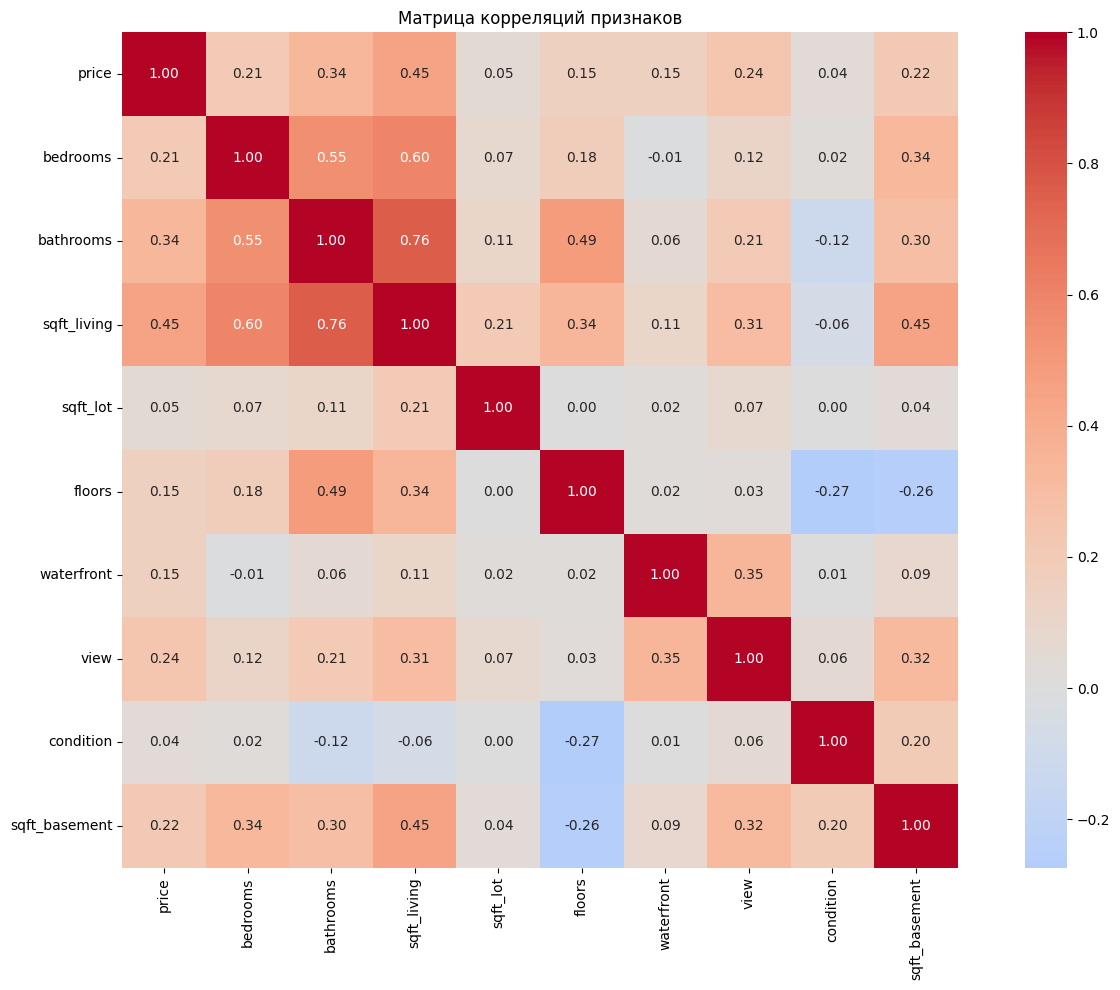

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Корреляционная матрица
corr_matrix = df_clean.corr()

# Вывод численных значений
print(corr_matrix.round(3))

# Визуализация
plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Матрица корреляций признаков")
plt.tight_layout()
plt.show()

Расчет VIF-коэффициента для каждого независимого признака

In [14]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Независимые признаки
X = df_clean.drop(columns=['price'])

# Добавляем константу для корректного расчета VIF
X_const = sm.add_constant(X)

# Расчет VIF
vif_data = pd.DataFrame()
vif_data['Признак'] = X_const.columns
vif_data['VIF'] = [
    variance_inflation_factor(X_const.values, i)
    for i in range(X_const.shape[1])
]

# Константу в итоговой таблице не показываем
vif_data = vif_data[vif_data['Признак'] != 'const']

print(vif_data)

         Признак       VIF
1       bedrooms  1.670615
2      bathrooms  2.903353
3    sqft_living  3.285435
4       sqft_lot  1.075567
5         floors  1.817264
6     waterfront  1.142496
7           view  1.313264
8      condition  1.113725
9  sqft_basement  1.809102


Корреляционная матрица показывает наличие умеренных линейных связей между некоторыми независимыми признаками, в частности между bathrooms и sqft_living (r = 0,76), bedrooms и sqft_living (r = 0,60), а также bedrooms и bathrooms (r = 0,55). Однако после удаления признака sqft_above, ранее создававшего точную линейную зависимость, значения VIF для всех оставшихся признаков стали ниже 5. Максимальный VIF составляет около 3,29 для sqft_living. Следовательно, существенной мультиколлинеарности в итоговом наборе признаков не наблюдается, и данные могут быть использованы для построения регрессионных моделей.

Разделяем датасет на тренировочную и тестовую выборки 80/20. 

In [15]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

# Независимые признаки
X = df_clean.drop(columns=['price'])

# Целевая переменная
y = df_clean['price']

print("Размер X:", X.shape)
print("Размер y:", y.shape)

Размер X: (4551, 9)
Размер y: (4551,)


Деление на выборки

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (3640, 9)
X_test: (911, 9)
y_train: (3640,)
y_test: (911,)


Для построения регрессионных моделей данные были разделены на обучающую и тестовую выборки в соотношении 80/20 с использованием train_test_split.

4. Ход работы

Кросс-валидация (делим на 5 частей)

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

Линейная регрессия

In [18]:
linear_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])

Ridge-регрессия

In [19]:
ridge_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Ridge())
])

alpha_grid = {
    'model__alpha': np.logspace(-3, 6, 10)
}

ridge_search = GridSearchCV(
    estimator=ridge_model,
    param_grid=alpha_grid,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    n_jobs=-1
)

ridge_search.fit(X_train, y_train)

print("Лучший alpha для Ridge:",
      ridge_search.best_params_['model__alpha'])

Лучший alpha для Ridge: 0.001


Lasso-регрессия

In [20]:
lasso_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Lasso(max_iter=100000))
])

lasso_search = GridSearchCV(
    estimator=lasso_model,
    param_grid=alpha_grid,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    n_jobs=-1
)

lasso_search.fit(X_train, y_train)

print("Лучший alpha для Lasso:",
      lasso_search.best_params_['model__alpha'])

Лучший alpha для Lasso: 100.0


Кросс-валидация моделей

In [21]:
scoring = {
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2',
    'MAPE': 'neg_mean_absolute_percentage_error'
}

models = {
    'Linear Regression': linear_model,
    'Lasso': lasso_search.best_estimator_,
    'Ridge': ridge_search.best_estimator_
}

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        'Model': name,
        'CV RMSE': -scores['test_RMSE'].mean(),
        'CV R2': scores['test_R2'].mean(),
        'CV MAPE (%)': -scores['test_MAPE'].mean() * 100
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df

,Model,CV RMSE,CV R2,CV MAPE (%)
0,Linear Regression,422251.914435,0.422203,35.613793
1,Lasso,422245.068521,0.422250,35.606367
2,Ridge,422251.915681,0.422204,35.613791


Обучение на тренировочной выборке и проверка на тестовой

In [22]:
test_results = []

for name, model in models.items():

    # Обучение
    model.fit(X_train, y_train)

    # Предсказание
    y_pred = model.predict(X_test)

    # Метрики
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100

    test_results.append({
        'Model': name,
        'RMSE': rmse,
        'R2': r2,
        'MAPE (%)': mape
    })

test_results_df = pd.DataFrame(test_results)

test_results_df

,Model,RMSE,R2,MAPE (%)
0,Linear Regression,249456.567524,0.581714,35.939796
1,Lasso,249436.776042,0.581780,35.936031
2,Ridge,249456.560825,0.581714,35.939795


Вывод: Для оценки устойчивости моделей применялась 5-кратная кросс-валидация. Были построены модели линейной регрессии, Lasso-регрессии и Ridge-регрессии. Для Lasso и Ridge перед обучением выполнялась стандартизация признаков, а коэффициент регуляризации alpha подбирался с использованием GridSearchCV.

На тестовой выборке все три модели продемонстрировали близкие результаты. Коэффициент детерминации R² составил приблизительно 0,58, то есть модели объясняют около 58% вариации целевой переменной price. RMSE составил около 249 тыс., а MAPE — около 36%. Применение Lasso и Ridge не привело к существенному улучшению качества по сравнению с обычной линейной регрессией. При этом значения RMSE при кросс-валидации оказались выше вследствие наличия в датасете экстремально дорогих объектов, к которым метрика RMSE особенно чувствительна.

График остатков моделей

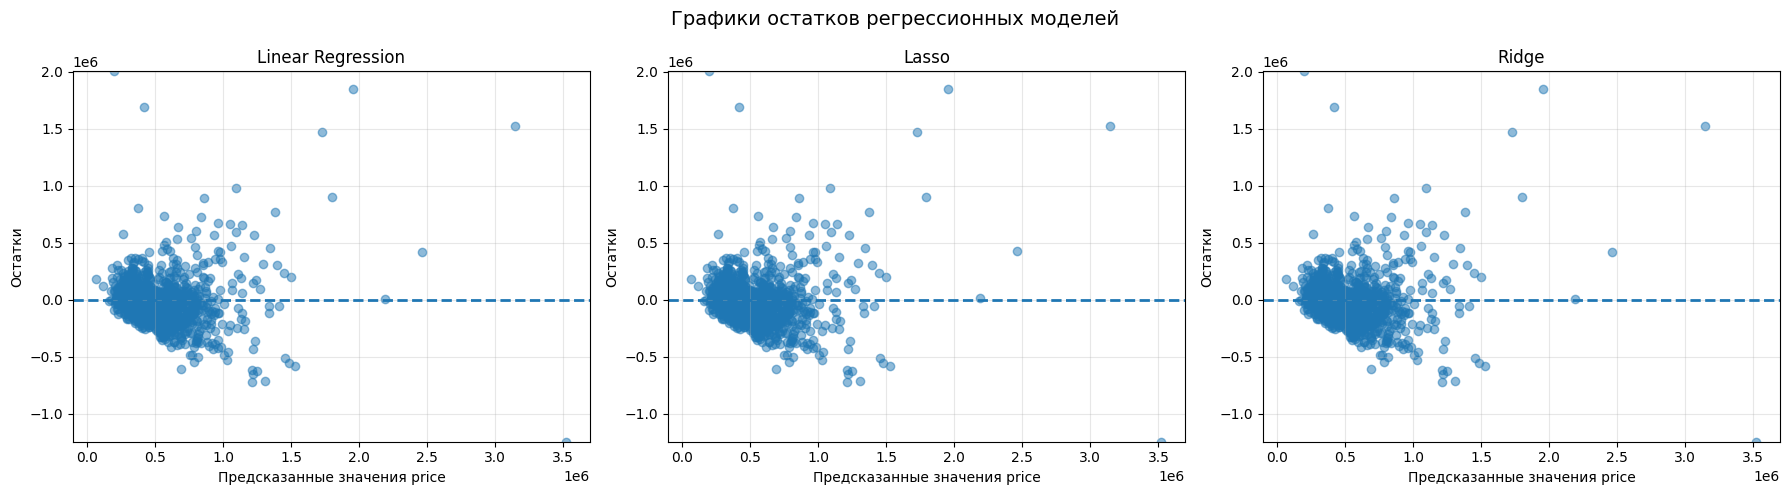

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

all_residuals = []

# Сначала сохраняем предсказания и остатки
residual_data = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    residuals = y_test - y_pred

    residual_data[name] = (y_pred, residuals)

    all_residuals.extend(residuals)

# Общие границы оси Y
y_min = min(all_residuals)
y_max = max(all_residuals)

# Строим графики
for ax, (name, (y_pred, residuals)) in zip(
    axes,
    residual_data.items()
):

    ax.scatter(
        y_pred,
        residuals,
        alpha=0.5
    )

    ax.axhline(
        y=0,
        linestyle='--',
        linewidth=2
    )

    ax.set_ylim(y_min, y_max)

    ax.set_title(name)
    ax.set_xlabel('Предсказанные значения price')
    ax.set_ylabel('Остатки')

    ax.grid(alpha=0.3)

plt.suptitle(
    'Графики остатков регрессионных моделей',
    fontsize=14
)

plt.tight_layout()
plt.show()

Вывод: Для линейной, Lasso- и Ridge-регрессии структура остатков оказалась практически одинаковой, что согласуется с близкими значениями метрик качества этих моделей.

Остатки располагаются как выше, так и ниже нулевой линии, однако их разброс не является постоянным. При увеличении прогнозируемой стоимости недвижимости наблюдается увеличение разброса ошибок, а также присутствуют отдельные наблюдения с большими положительными и отрицательными остатками. Такая структура свидетельствует о наличии гетероскедастичности, то есть дисперсия ошибок модели зависит от уровня прогнозируемой переменной.


Стандартизация данных

In [24]:
from sklearn.preprocessing import StandardScaler

# Создаем объект стандартизации
scaler = StandardScaler()

# Обучаем scaler только на тренировочной выборке
X_train_scaled = scaler.fit_transform(X_train)

# Тестовую выборку только преобразуем
X_test_scaled = scaler.transform(X_test)

print("Размер X_train_scaled:", X_train_scaled.shape)
print("Размер X_test_scaled:", X_test_scaled.shape)

Размер X_train_scaled: (3640, 9)
Размер X_test_scaled: (911, 9)


PCA

In [25]:
from sklearn.decomposition import PCA

# PCA со всеми компонентами
pca = PCA()

# Обучаем PCA только на тренировочной выборке
X_train_pca_all = pca.fit_transform(X_train_scaled)

# Доля объясненной дисперсии каждой компоненты
explained_variance = pca.explained_variance_ratio_

# Накопленная доля объясненной дисперсии
cumulative_variance = np.cumsum(explained_variance)

print("Доля объясненной дисперсии:")
for i, value in enumerate(explained_variance, start=1):
    print(f"PC{i}: {value:.4f} ({value * 100:.2f}%)")

Доля объясненной дисперсии:
PC1: 0.3094 (30.94%)
PC2: 0.1791 (17.91%)
PC3: 0.1363 (13.63%)
PC4: 0.1099 (10.99%)
PC5: 0.0844 (8.44%)
PC6: 0.0718 (7.18%)
PC7: 0.0527 (5.27%)
PC8: 0.0317 (3.17%)
PC9: 0.0247 (2.47%)


График каменистой осыпи

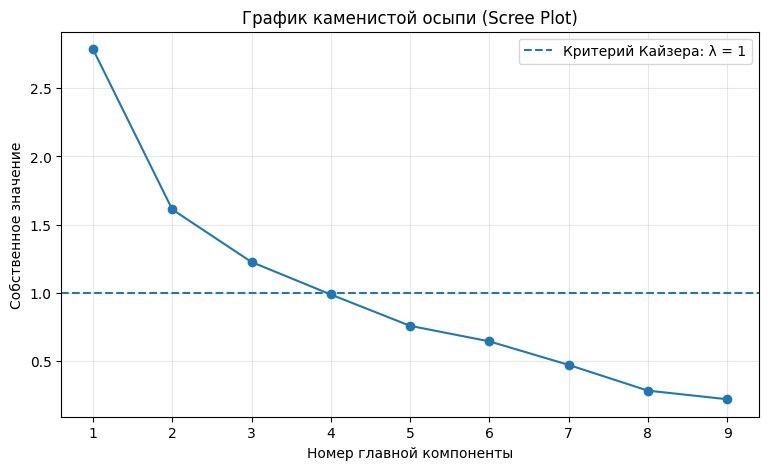

In [26]:
import matplotlib.pyplot as plt

# Собственные значения компонент
eigenvalues = pca.explained_variance_

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(eigenvalues) + 1),
    eigenvalues,
    marker='o'
)

# Критерий Кайзера
plt.axhline(
    y=1,
    linestyle='--',
    label='Критерий Кайзера: λ = 1'
)

plt.xlabel('Номер главной компоненты')
plt.ylabel('Собственное значение')
plt.title('График каменистой осыпи (Scree Plot)')
plt.xticks(range(1, len(eigenvalues) + 1))
plt.grid(alpha=0.3)
plt.legend()

plt.show()

По критерию Кайзера результат даёт основание оставить первые 3 компонента, но они обьясняют только 62,5% дисперсии. Поэтому, строим график накопленной объяснённой дисперсии.

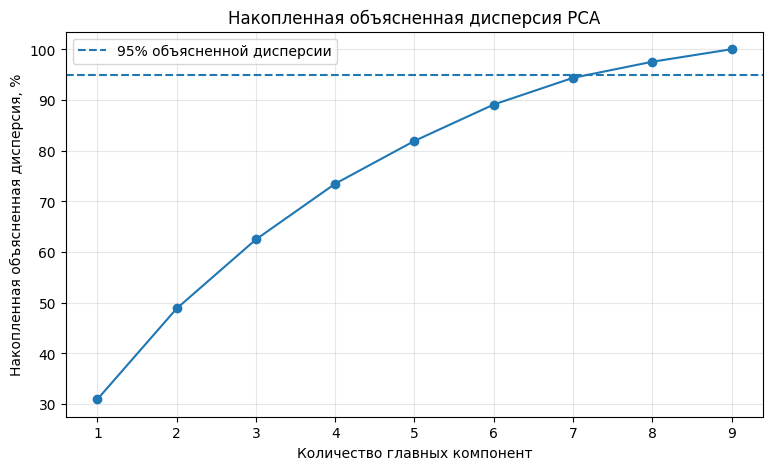

In [27]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker='o'
)

plt.axhline(
    y=95,
    linestyle='--',
    label='95% объясненной дисперсии'
)

plt.xlabel('Количество главных компонент')
plt.ylabel('Накопленная объясненная дисперсия, %')
plt.title('Накопленная объясненная дисперсия PCA')
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.grid(alpha=0.3)
plt.legend()

plt.show()

Согласно этому графику мы уже можем оставить 8 критериев, что обьясняет 95% дисперсии. 

In [28]:
pca_final = PCA(n_components=8)

# Обучение на тренировочной выборке
X_train_pca = pca_final.fit_transform(X_train_scaled)

# Преобразование тестовой выборки
X_test_pca = pca_final.transform(X_test_scaled)

print("Размер до PCA:", X_train_scaled.shape)
print("Размер после PCA:", X_train_pca.shape)

Размер до PCA: (3640, 9)
Размер после PCA: (3640, 8)


Проверка устранения мультиколлинеарности

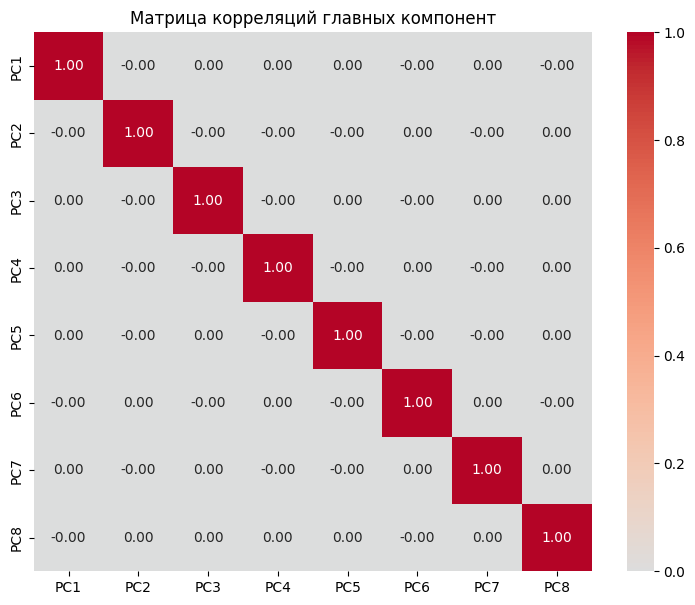

In [29]:
pca_columns = [
    f'PC{i}'
    for i in range(1, X_train_pca.shape[1] + 1)
]

pca_df = pd.DataFrame(
    X_train_pca,
    columns=pca_columns
)

pca_corr = pca_df.corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    pca_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Матрица корреляций главных компонент')
plt.show()

Вывод: Перед применением метода главных компонент была выполнена стандартизация независимых признаков с помощью StandardScaler, поскольку PCA чувствителен к масштабу переменных. Параметры стандартизации определялись только по тренировочной выборке, после чего те же параметры применялись к тестовой выборке.

Далее был проведён анализ главных компонент. Согласно графику каменистой осыпи, первые несколько компонент содержат наибольшую долю информации. Первые три компоненты имеют собственные значения около или выше единицы и в совокупности объясняют приблизительно 62.5% дисперсии. Анализ накопленной объяснённой дисперсии показал, что для сохранения не менее 95% информации необходимо использовать 8 главных компонент, которые объясняют приблизительно 97.5% общей дисперсии.

Полученные главные компоненты являются взаимно ортогональными, благодаря чему мультиколлинеарность между признаками устраняется.

Построение регрессии с использованием главных компонентов

In [30]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.model_selection import KFold, GridSearchCV, cross_validate

from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

Настраиваем PCA-модели

In [31]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Линейная регрессия + PCA
linear_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=8)),
    ('model', LinearRegression())
])

# Lasso + PCA
lasso_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=8)),
    ('model', Lasso(max_iter=100000))
])

# Ridge + PCA
ridge_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=8)),
    ('model', Ridge())
])

Подбираем alpha для Lasso и Ridge

In [32]:
alpha_grid = {
    'model__alpha': np.logspace(-3, 6, 10)
}

lasso_pca_search = GridSearchCV(
    estimator=lasso_pca,
    param_grid=alpha_grid,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    n_jobs=-1
)

ridge_pca_search = GridSearchCV(
    estimator=ridge_pca,
    param_grid=alpha_grid,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    n_jobs=-1
)

lasso_pca_search.fit(X_train, y_train)
ridge_pca_search.fit(X_train, y_train)

print(
    "Лучший alpha для Lasso + PCA:",
    lasso_pca_search.best_params_['model__alpha']
)

print(
    "Лучший alpha для Ridge + PCA:",
    ridge_pca_search.best_params_['model__alpha']
)

Лучший alpha для Lasso + PCA: 0.001
Лучший alpha для Ridge + PCA: 100.0


Кросс-валидация

In [33]:
models_pca = {
    'Linear Regression': linear_pca,
    'Lasso': lasso_pca_search.best_estimator_,
    'Ridge': ridge_pca_search.best_estimator_
}

scoring = {
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2',
    'MAPE': 'neg_mean_absolute_percentage_error'
}

cv_pca_results = []

for name, model in models_pca.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_pca_results.append({
        'Model': name,
        'CV RMSE': -scores['test_RMSE'].mean(),
        'CV R2': scores['test_R2'].mean(),
        'CV MAPE (%)': -scores['test_MAPE'].mean() * 100
    })

cv_pca_results_df = pd.DataFrame(cv_pca_results)

print(cv_pca_results_df)

               Model        CV RMSE     CV R2  CV MAPE (%)
0  Linear Regression  437569.350121  0.364775    38.218212
1              Lasso  437569.350122  0.364775    38.218211
2              Ridge  437312.874434  0.366196    38.113602


Проверка модели на тестовой выборке

In [34]:
test_pca_results = []

for name, model in models_pca.items():

    # Обучаем модель
    model.fit(X_train, y_train)

    # Предсказание
    y_pred = model.predict(X_test)

    # Метрики
    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    r2 = r2_score(
        y_test,
        y_pred
    )

    mape = (
        mean_absolute_percentage_error(
            y_test,
            y_pred
        ) * 100
    )

    test_pca_results.append({
        'Model': name,
        'RMSE': rmse,
        'R2': r2,
        'MAPE (%)': mape
    })

pca_results_df = pd.DataFrame(test_pca_results)

print(pca_results_df)

               Model           RMSE        R2   MAPE (%)
0  Linear Regression  260120.256021  0.545188  38.284363
1              Lasso  260120.255915  0.545188  38.284363
2              Ridge  260026.679553  0.545515  38.193770


Сравнение исходных признаков и РСА

In [35]:
original_results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Lasso',
        'Ridge'
    ],
    'RMSE original': [
        249456.57,
        249436.78,
        249456.56
    ],
    'R2 original': [
        0.5817,
        0.5818,
        0.5817
    ],
    'MAPE original (%)': [
        35.94,
        35.94,
        35.94
    ]
})

pca_compare = pca_results_df.rename(columns={
    'RMSE': 'RMSE PCA',
    'R2': 'R2 PCA',
    'MAPE (%)': 'MAPE PCA (%)'
})

comparison = original_results.merge(
    pca_compare,
    on='Model'
)

comparison 

comparison['RMSE change'] = (
    comparison['RMSE PCA']
    - comparison['RMSE original']
)

comparison['R2 change'] = (
    comparison['R2 PCA']
    - comparison['R2 original']
)

comparison['MAPE change'] = (
    comparison['MAPE PCA (%)']
    - comparison['MAPE original (%)']
)

comparison.round(4)

,Model,RMSE original,R2 original,MAPE original (%),RMSE PCA,R2 PCA,MAPE PCA (%),RMSE change,R2 change,MAPE change
0,Linear Regression,249456.57,0.5817,35.94,260120.2560,0.5452,38.2844,10663.6860,-0.0365,2.3444
1,Lasso,249436.78,0.5818,35.94,260120.2559,0.5452,38.2844,10683.4759,-0.0366,2.3444
2,Ridge,249456.56,0.5817,35.94,260026.6796,0.5455,38.1938,10570.1196,-0.0362,2.2538


5. Итоговый вывод

В данной лабораторной работе на примере датасета о стоимости жилой недвижимости была исследована задача регрессионного прогнозирования цены объекта (price) по его числовым характеристикам. В ходе работы были выполнены первичный анализ и предобработка данных, исследование мультиколлинеарности, построение линейных моделей, анализ остатков, а также снижение размерности методом главных компонент.

Анализ данных и предобработка.
Исходный датасет содержал 4600 наблюдений и 18 признаков. В ходе первичного анализа было установлено, что целевая переменная price имеет выраженную правостороннюю асимметрию и содержит отдельные объекты с очень высокой стоимостью. Из данных были удалены категориальные признаки city, statezip и street, столбец date, признаки yr_built и yr_renovated, а также price_per_sqft, поскольку данный показатель напрямую рассчитывается через price и создаёт утечку целевой переменной. Кроме того, были исключены 49 объектов с нулевой ценой, поскольку такие значения делают некорректным расчёт MAPE. После предобработки осталось 4551 наблюдение.

Корреляционный анализ и мультиколлинеарность.
Корреляционная матрица показала, что наиболее сильная положительная связь с ценой наблюдается у sqft_living (около 0,45), sqft_above (около 0,38) и bathrooms (около 0,34). При расчёте VIF для sqft_living, sqft_above и sqft_basement были получены чрезвычайно высокие значения . Это связано с точной линейной зависимостью. 
После удаления sqft_above все VIF стали ниже 5. Максимальное значение составило около 3,29 для sqft_living, что позволило сделать вывод об отсутствии существенной мультиколлинеарности в итоговом наборе признаков.

Регрессионные модели на исходных признаках.
Данные были разделены на обучающую и тестовую выборки в соотношении 80/20. Для оценки устойчивости моделей применялась 5-кратная кросс-валидация. Были построены модели линейной регрессии, Lasso и Ridge. На тестовой выборке все три модели показали практически одинаковое качество. Для линейной регрессии RMSE составил около 249,5 тыс., \(R^2\) — около 0,582, MAPE — около 35,9%. Lasso показала незначительно лучший результат: RMSE около 249,4 тыс. и \(R^2\) около 0,582. Таким образом, модели объясняют примерно 58% вариации стоимости недвижимости, однако относительная ошибка прогноза остаётся достаточно высокой.

Анализ остатков.
Для всех трёх моделей были построены графики остатков относительно предсказанных значений с горизонтальной линией на уровне нуля. Остатки распределены как выше, так и ниже нулевой линии, однако их разброс увеличивается при росте прогнозируемой стоимости недвижимости. Такая структура указывает на наличие гетероскедастичности, то есть дисперсия ошибки модели не является постоянной. Кроме того, на графиках присутствуют отдельные наблюдения с крупными остатками, что согласуется с наличием дорогостоящих объектов и сильной правосторонней асимметрией price.

PCA и модели на главных компонентах.
Перед применением PCA признаки были стандартизированы с помощью StandardScaler. По графику каменистой осыпи и анализу накопленной объяснённой дисперсии было выбрано 8 главных компонент, сохраняющих приблизительно 97,5% общей дисперсии исходных данных. PCA позволил заменить исходные взаимосвязанные признаки ортогональными компонентами и уменьшить размерность с 9 до 8 признаков. Однако качество моделей несколько снизилось. Для моделей на PCA значение RMSE составило около 260 тыс., \(R^2\) — около 0,545, а MAPE — около 38,2%. Лучший результат среди моделей с PCA показала Ridge-регрессия с \(R^2\) около 0,546.

Итоговый выбор модели.
По совокупности RMSE, \(R^2\) и MAPE модели на исходных признаках оказались лучше моделей, построенных на главных компонентах. Формально наилучшие показатели получила Lasso-регрессия на исходных признаках, однако различия между Lasso, Ridge и обычной линейной регрессией крайне малы. Поэтому линейная регрессия также может рассматриваться как предпочтительная базовая модель благодаря простоте и интерпретируемости. Применение PCA в данном случае устранило корреляцию между признаками и уменьшило размерность, но не повысило точность прогнозирования.
Перспективным направлением дальнейшего улучшения модели является логарифмическое преобразование целевой переменной price, например log1p(price), что может снизить влияние дорогих объектов и уменьшить гетероскедастичность. Также можно исследовать нелинейные зависимости и взаимодействия между признаками, использовать более сложные методы машинного обучения — Random Forest, Gradient Boosting или XGBoost — и отдельно проанализировать влияние выбросов на качество прогнозирования.

6. Список источников

1. Датасет House Pricing Prediction: https://www.kaggle.com/datasets/debayank2024/house-price-prediction
2. Указания к лабораторной работе 1: https://dispace.nstu.ru/course/965/9020/23586
